## Test training


In [1]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.sampler
%aimport quantdata.dysanos
%aimport quantdata.utils.backbone
%aimport quantdata.torch
%aimport quantdata.torch.bbtorch
%aimport quantdata.torch.ffw
%aimport quantdata.dysanos.simple
%aimport quantdata.dysanos.simple.sampler
%aimport quantdata.dysanos.simple.model
%aimport quantdata.dysanos.simple.trainer
%aimport quantdata.dysanos.simple.aec

from quantdata.dysanos.simple.aec import load_data
sampler = load_data(["SPX"])
print("/done")



00: Importing torch...done; this took 0.00286ms.
00: Generating samples for 1 tickers SPX with from 2015-01-01 to 2025-07-01... done; this took 0.27s.
00: Found the following number of samples per ticker: SPX: 2617.
00: Found date range 2015-01-02 to 2025-07-01 with 2617 total dates. First validation date for 25 steps per sample is 2023-05-01.
00: Using up to 1000 options per date.
01:   Ticker SPX: using 411 training samples (accross 2079 training dates), and 103 validation samples (accross 538 validation dates).
00: Created 411 training samples and 103 validation samples based on the date split at 2023-05-01. That implies 20% of all samples are validation samples.
00: Total time taken: 0.3s.
/done


## AEC

Cleaning up memory... done.
Model AEC train_vol_vol_simple 1.2 [5b3e12a5|acaee5f1ce9f88de] created.
00: Trainer for 'AEC train_vol_vol_simple 1.2 [5b3e12a5|acaee5f1ce9f88de]'
00: ======================================================================
01:   Model is ready. Current epoch to train is 0.
01:   Experiment path is /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_simple 01994b44/.
00: Launching 'AEC train_vol_vol_simple 1.2 [5b3e12a5|acaee5f1ce9f88de]' training for 1000 epochs over 411 training and 103 validation samples, using a mini bastch size of 128 for 100 batches per epoch, and a batch size of 512 for valuation.
01:   This model has 30689 parameters.
01:   Starting afresh.
00: Training epoch 1/1000 error avg trn 481.8 [22s] learning rate 1.00e-03 grad norm 4.562... running valuation... 

V0502 22:09:50.024000 23944 torch/_dynamo/guards.py:4760] [2/1] [__recompiles] Recompiling function valuation in /home/hans/python/quant_data/quantdata/dysanos/simple/trainer.py:310
V0502 22:09:50.024000 23944 torch/_dynamo/guards.py:4760] [2/1] [__recompiles]     triggered by the following guard failure(s):
V0502 22:09:50.024000 23944 torch/_dynamo/guards.py:4760] [2/1] [__recompiles]     - 2/0: tensor 'batch['ask_pure_price']' size mismatch at index 0. expected 411, actual 103


00: Training 'train_vol_vol_simple' epoch 1/1000 error avg trn 481.8; val 50.34/62.5 [22s 5s 5s]. LR: 1.00e-03, GN 4.562, excess_weighted: 0.00347/0.003012, excess_weighted_avg: 0.004074/0.003201, excess_spread: 54.99/62.65, excess_spread_avg: 52.09/62.65, excess: 0.005553/0.003641, excess_avg: 0.005303/0.003641. ETA: 9:34:49.
01:   Epoch 1: Saving new best validation loss 62.5 to '/media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_simple 01994b44/best.pt'... done; this took 3.31ms.
01:   Saving checkpoint to /media/storage/quantdata/experiments/dysanos/simple/acaee5f1ce9f88de/v1/train_vol_vol_simple 01994b44/last.pt... done; this took 2.51ms.


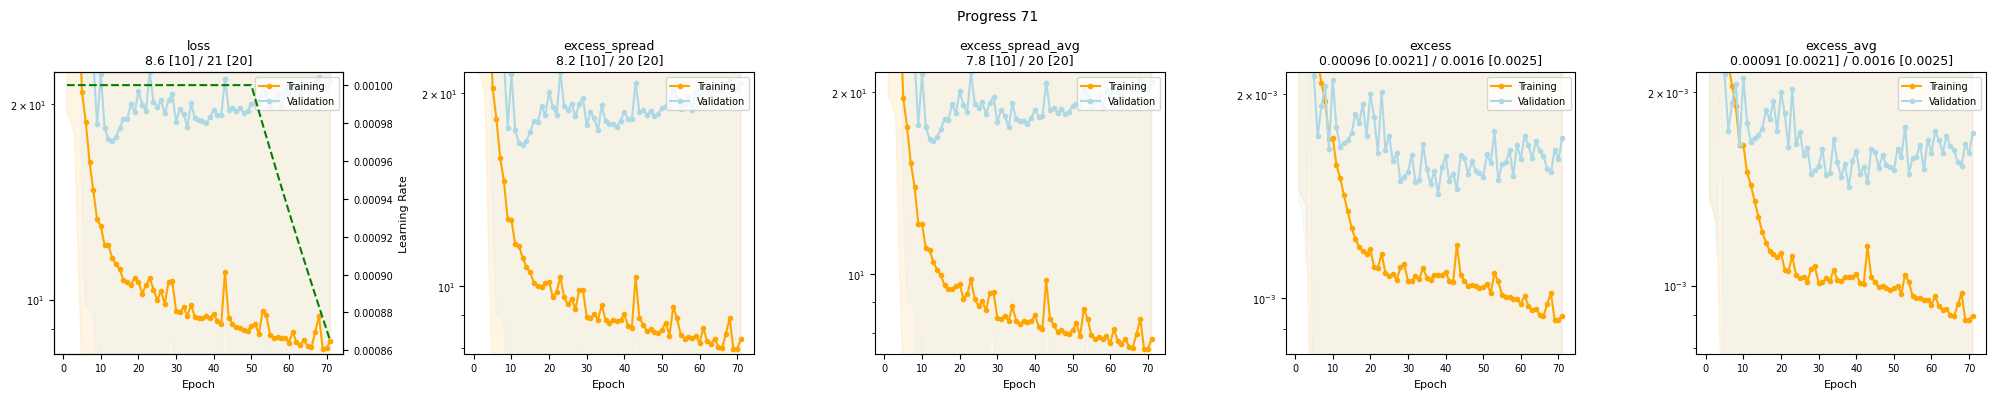

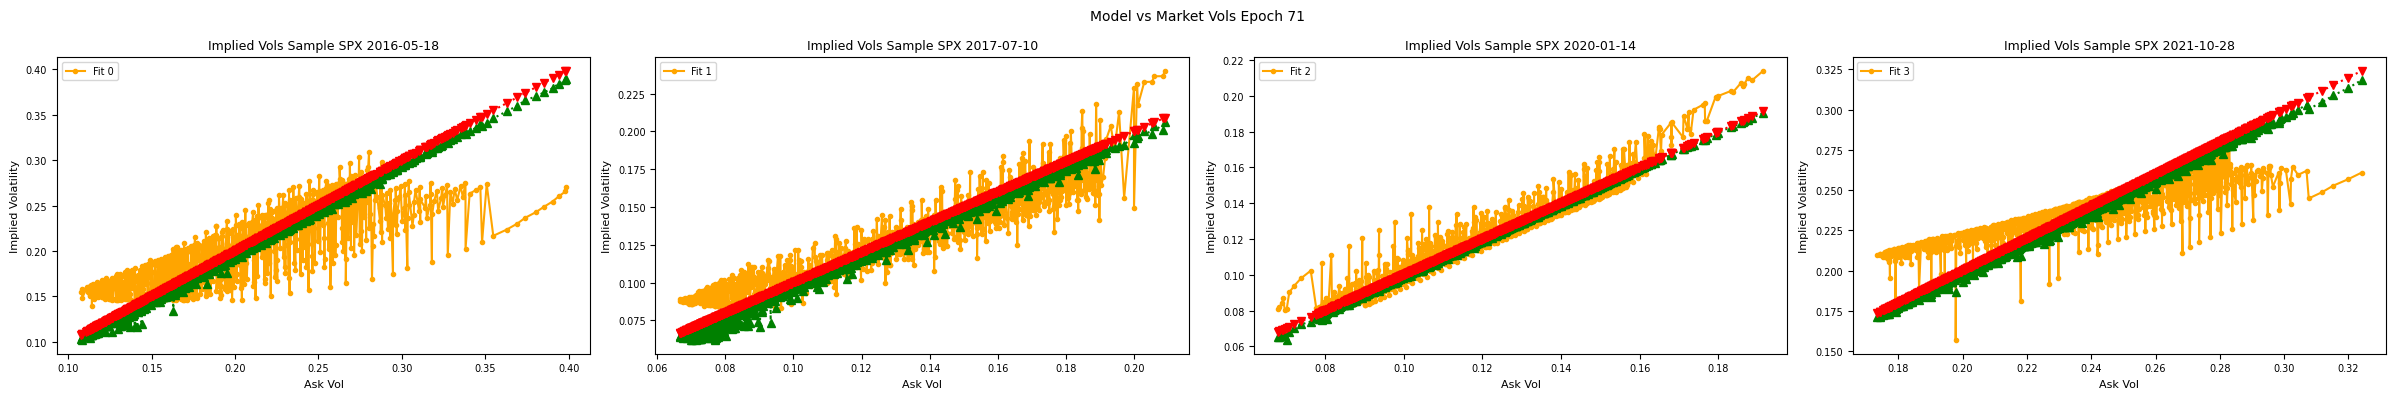

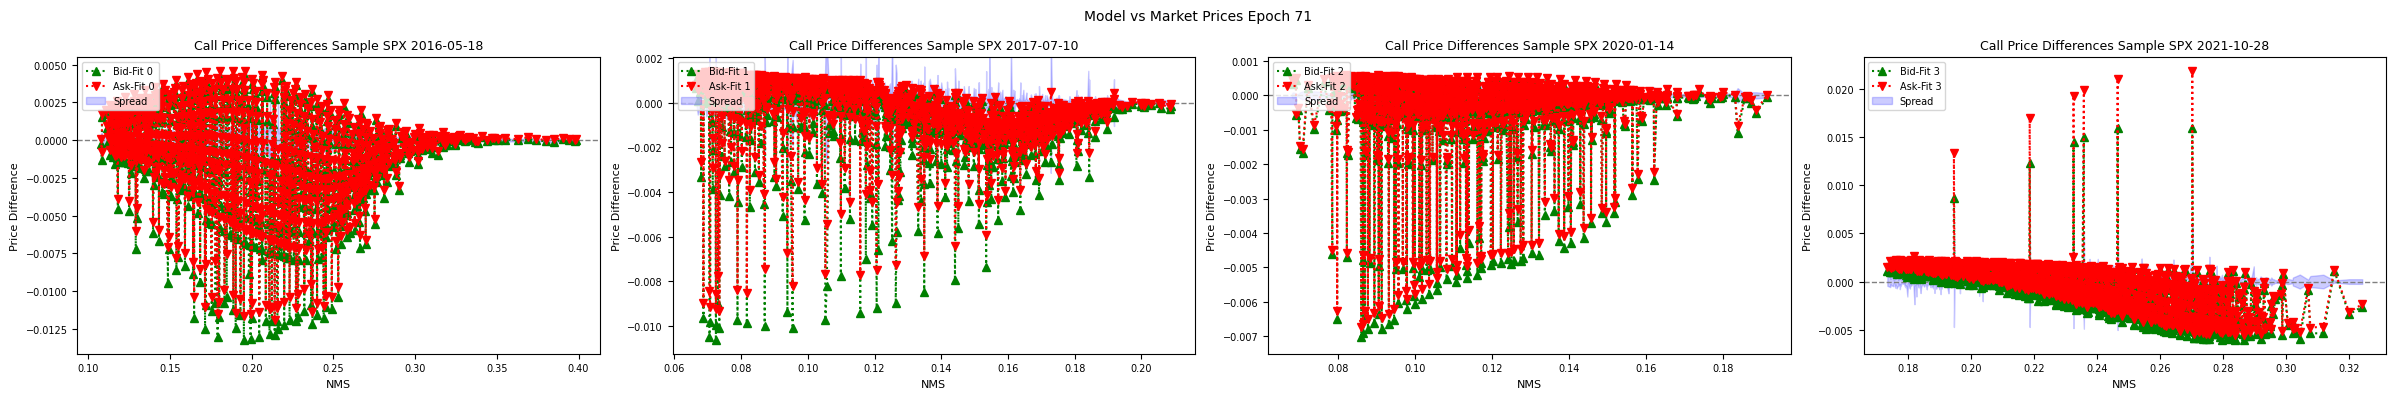

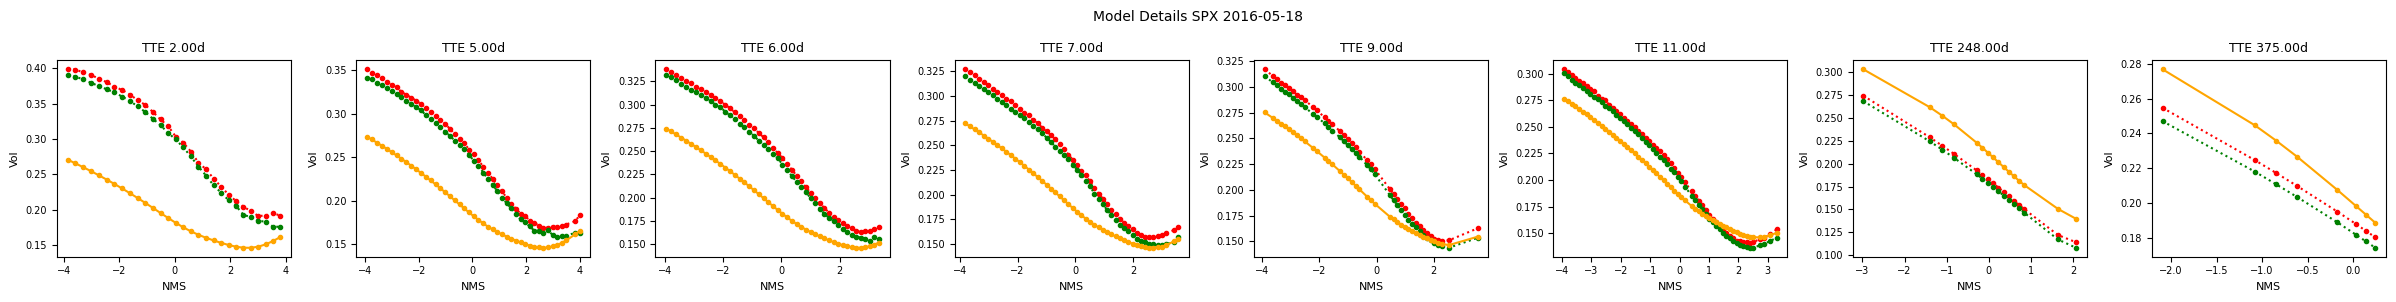

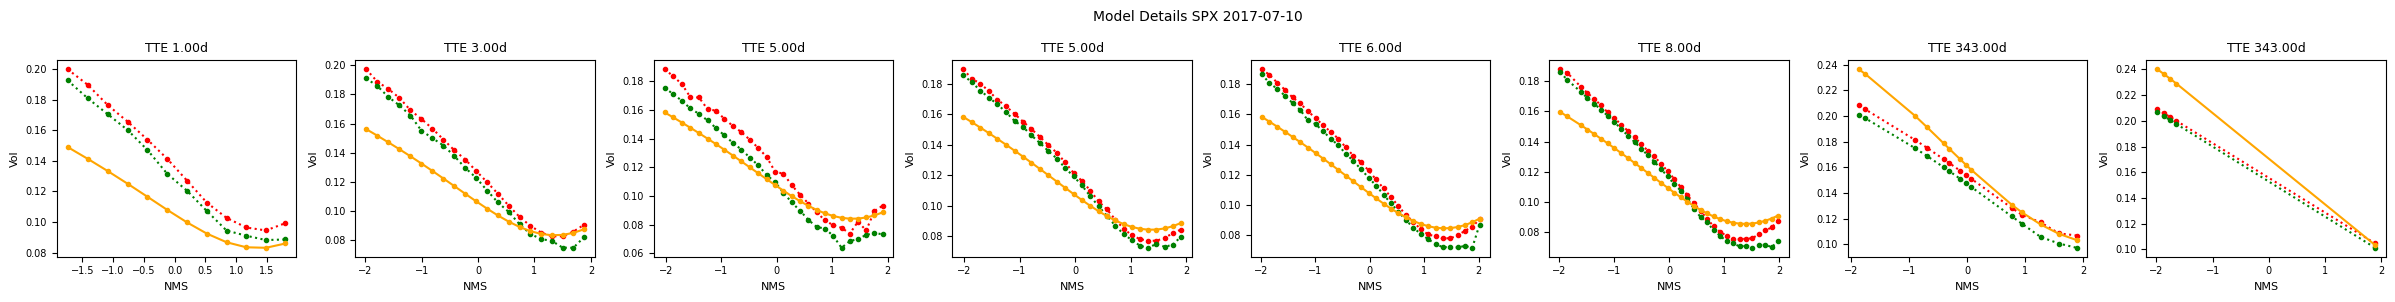

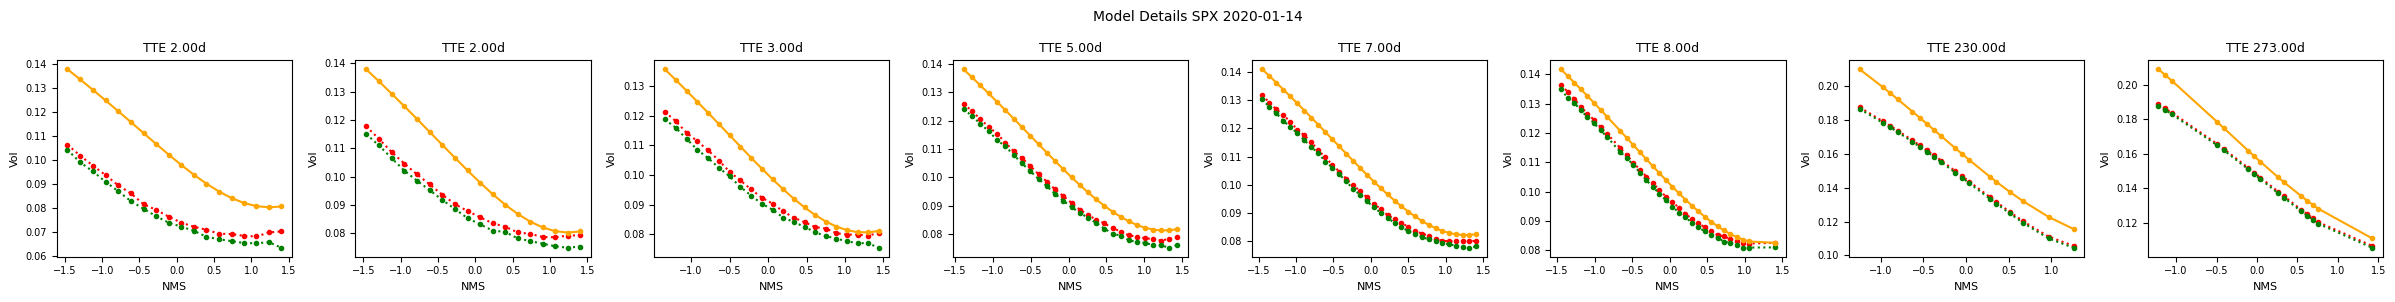

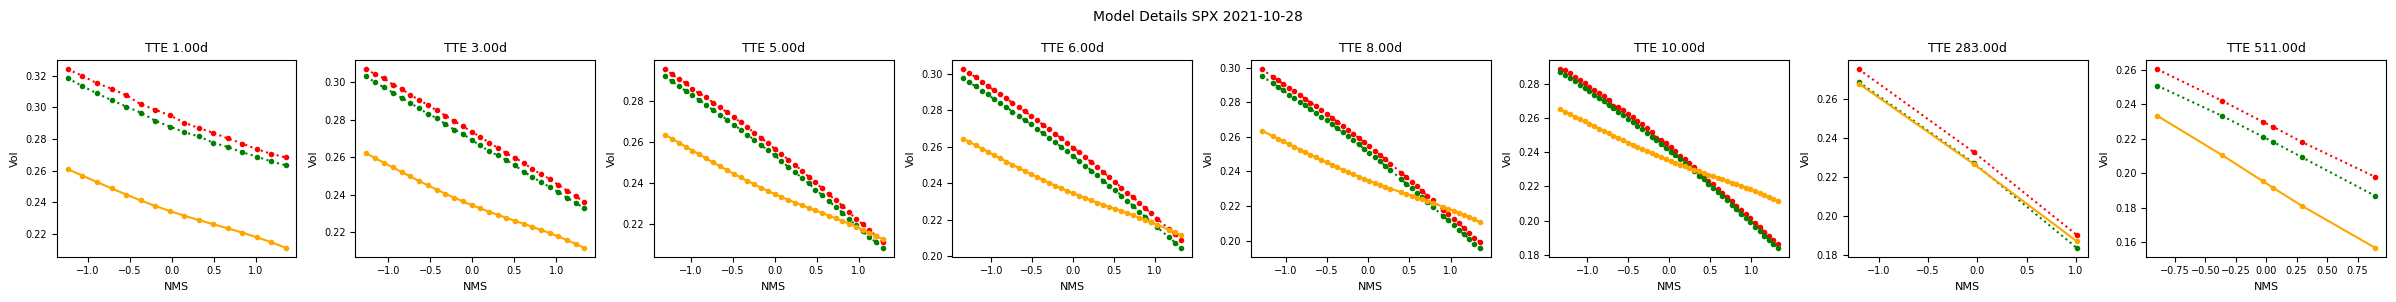

00: Training 'train_vol_vol_simple' epoch 2/1000 error avg trn 49.97; val 49.35/60.2 [15s 3s 2s]. LR: 1.00e-03, GN 3.214, excess_weighted: 0.003366/0.002895, excess_weighted_avg: 0.003983/0.003094, excess_spread: 53.35/60.21, excess_spread_avg: 50.44/60.21, excess: 0.005378/0.003498, excess_avg: 0.005122/0.003498. ETA: 12:54:57.
00: Training 'train_vol_vol_simple' epoch 3/1000 error avg trn 50.2; val 48.98/53.05 [13s 2s 2s]. LR: 1.00e-03, GN 33.35, excess_weighted: 0.003279/0.002535, excess_weighted_avg: 0.003983/0.002822, excess_spread: 51.96/52.73, excess_spread_avg: 49/52.73, excess: 0.005357/0.003232, excess_avg: 0.005088/0.003232. ETA: 16:03:05.
00: Training 'train_vol_vol_simple' epoch 4/1000 error avg trn 49.18; val 30.18/88.12 [12s 1.7s 1.5s]. LR: 1.00e-03, GN 85.26, excess_weighted: 0.001868/0.004271, excess_weighted_avg: 0.002327/0.004273, excess_spread: 29.6/88.85, excess_spread_avg: 28.48/88.85, excess: 0.003139/0.005597, excess_avg: 0.003119/0.005597. ETA: 19:11:28.
00: Tr

In [ ]:
from quantdata.dysanos.simple.model import *
from quantdata.dysanos.simple.aec import *

aec_config = AEC.Config(
    # core pararmeters
    encode_what = "vol",
    fit_what    = "vol",
    num_state   = 64,
    fit_average = True,

    encoder = DeepSetEncoderFactory(
        num_compress = 128,
        inside_tanh = True,
        set_config = FeedForward.Config(
            num_depth = 2,
            num_width = 32,
            activation = 'Softplus',
        ),
        fix_config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',
        )
    ),
    decoder = SimpleDecoderFactory(
        config = FeedForward.Config(
            num_depth = 2,
            num_width = 64,
            activation = 'Softplus',    
        )
    ),
)

run( ipynbname.name(), version="1.2", aec_config=aec_config, sampler=sampler, epochs = 1000, batch_per_epoch = 100, val_batch_size=512 )
